### **Step 1: Set up and load the data**

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('Fraud_Data.csv')
print(df.shape)
df.head()

(151112, 11)


,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,age,ip_address,class
0,22058,2015-02-24 22:55:49,2015-04-18 02:47:11,34,QVPSPJUOCKZAR,SEO,Chrome,M,39,7.327584e+08,0
1,333320,2015-06-07 20:39:50,2015-06-08 01:38:54,16,EOGFQPIZPYXFZ,Ads,Chrome,F,53,3.503114e+08,0
2,1359,2015-01-01 18:52:44,2015-01-01 18:52:45,15,YSSKYOSJHPPLJ,SEO,Opera,M,53,2.621474e+09,1
3,150084,2015-04-28 21:13:25,2015-05-04 13:54:50,44,ATGTXKYKUDUQN,SEO,Safari,M,41,3.840542e+09,0
4,221365,2015-07-21 07:09:52,2015-09-09 18:40:53,39,NAUITBZFJKHWW,Ads,Safari,M,45,4.155831e+08,0


In [ ]:
print("Data types:")
print(df.dtypes)

Data types:
user_id             int64
signup_time        object
purchase_time      object
purchase_value      int64
device_id          object
source             object
browser            object
sex                object
age                 int64
ip_address        float64
class               int64
dtype: object


In [ ]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,151112.0,2.001710e+05,1.153693e+05,2.000000,1.006425e+05,1.999580e+05,3.000540e+05,4.000000e+05
purchase_value,151112.0,3.693537e+01,1.832276e+01,9.000000,2.200000e+01,3.500000e+01,4.900000e+01,1.540000e+02
age,151112.0,3.314070e+01,8.617733e+00,18.000000,2.700000e+01,3.300000e+01,3.900000e+01,7.600000e+01
ip_address,151112.0,2.152145e+09,1.248497e+09,52093.496895,1.085934e+09,2.154770e+09,3.243258e+09,4.294850e+09
class,151112.0,9.364577e-02,2.913362e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


### **Step 2: Check the data types, missing values and duplicates**

In [ ]:
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151112 entries, 0 to 151111
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   user_id         151112 non-null  int64  
 1   signup_time     151112 non-null  object 
 2   purchase_time   151112 non-null  object 
 3   purchase_value  151112 non-null  int64  
 4   device_id       151112 non-null  object 
 5   source          151112 non-null  object 
 6   browser         151112 non-null  object 
 7   sex             151112 non-null  object 
 8   age             151112 non-null  int64  
 9   ip_address      151112 non-null  float64
 10  class           151112 non-null  int64  
dtypes: float64(1), int64(4), object(6)
memory usage: 12.7+ MB

Missing values per column:
user_id           0
signup_time       0
purchase_time     0
purchase_value    0
device_id         0
source            0
browser           0
sex               0
age               0
ip_address        0


### **Step 3: Convert the date columns**

In [ ]:
df['signup_time'] = pd.to_datetime(df['signup_time'])
df['purchase_time'] = pd.to_datetime(df['purchase_time'])

df[['signup_time', 'purchase_time']].info()
print()
print("Earliest signup:", df['signup_time'].min())
print("Latest purchase:", df['purchase_time'].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151112 entries, 0 to 151111
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   signup_time    151112 non-null  datetime64[ns]
 1   purchase_time  151112 non-null  datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 2.3 MB

Earliest signup: 2015-01-01 00:00:42
Latest purchase: 2015-12-16 02:56:05


### **Step 4: Look at the target (class balance)**

class
0    136961
1     14151
Name: count, dtype: int64

class
0    90.64
1     9.36
Name: proportion, dtype: float64


<Axes: title={'center': 'Normal (0) vs Fraud (1)'}, xlabel='class'>

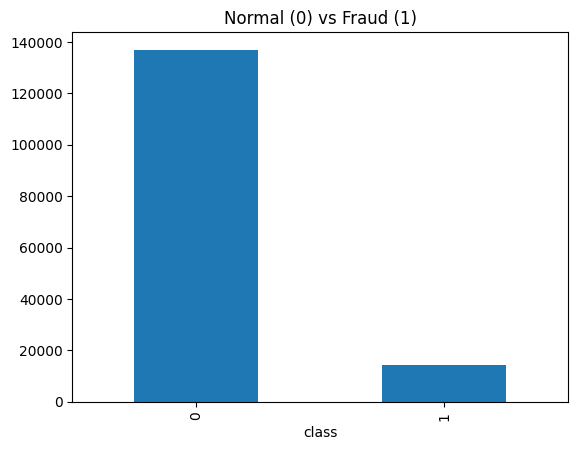

In [ ]:
print(df['class'].value_counts())
print()
print(df['class'].value_counts(normalize=True).round(4) * 100)

df['class'].value_counts().plot(kind='bar', title='Normal (0) vs Fraud (1)')

### **Step 5: Build your first feature (time gap)**

In [ ]:
df['time_since_signup'] = (df['purchase_time'] - df['signup_time']).dt.total_seconds()

print(df.groupby('class')['time_since_signup'].describe().round(0))

          count       mean        std    min        25%        50%        75%  \
class                                                                           
0      136961.0  5191179.0  2988589.0  137.0  2588829.0  5194911.0  7781319.0   
1       14151.0  2423842.0  3313789.0    1.0        1.0        1.0  4790510.0   

              max  
class              
0      10367972.0  
1      10363947.0  


### **Step 6: Check the fast purchases**

In [ ]:
fast = df[df['time_since_signup'] < 137]
print("Rows with gap under 137 seconds, by class:")
print(fast['class'].value_counts())
print()
print("Rows with gap of exactly 1 second:", (df['time_since_signup'] == 1).sum())

Rows with gap under 137 seconds, by class:
class
1    7600
Name: count, dtype: int64

Rows with gap of exactly 1 second: 7600


### **Step 7: Explore device sharing**

In [ ]:
users_per_device = df['device_id'].map(df['device_id'].value_counts())

print(df.groupby(users_per_device)['class'].agg(['count', 'mean']).round(3))

            count   mean
device_id               
1          131781  0.030
2           10654  0.229
3             270  0.244
4              16  0.625
5              65  0.800
6             174  0.828
7             350  0.860
8             552  0.875
9             702  0.889
10            920  0.899
11           1111  0.908
12           1080  0.919
13            832  0.922
14            798  0.927
15            615  0.924
16            576  0.934
17            221  0.937
18            180  0.939
19             95  0.947
20            120  0.950


### **Step 8: Is device sharing a different signal from the 1-second bots?**

In [ ]:
slow_fraud = df[(df['class'] == 1) & (df['time_since_signup'] > 1)]

print("Slow fraud rows:", len(slow_fraud))
print("Share of slow fraud on a shared device:",
      (users_per_device[slow_fraud.index] > 1).mean().round(3))

Slow fraud rows: 6551
Share of slow fraud on a shared device: 0.388


### **Step 9: Compare the three groups side by side**

In [ ]:
fast_fraud = df[(df['class'] == 1) & (df['time_since_signup'] <= 1)]
normal = df[df['class'] == 0]

print("Fast fraud on a shared device:", (users_per_device[fast_fraud.index] > 1).mean().round(3))
print("Slow fraud on a shared device:", (users_per_device[slow_fraud.index] > 1).mean().round(3))
print("Normal users on a shared device:", (users_per_device[normal.index] > 1).mean().round(3))

Fast fraud on a shared device: 1.0
Slow fraud on a shared device: 0.388
Normal users on a shared device: 0.067


### **Step 10: IP sharing**

In [ ]:
users_per_ip = df['ip_address'].map(df['ip_address'].value_counts())

print("Fraud rate by number of users on the same IP:")
print(df.groupby(users_per_ip)['class'].agg(['count', 'mean']).round(3).head(8))
print()
print("Fast fraud on a shared IP:  ", (users_per_ip[fast_fraud.index] > 1).mean().round(3))
print("Slow fraud on a shared IP:  ", (users_per_ip[slow_fraud.index] > 1).mean().round(3))
print("Normal users on a shared IP:", (users_per_ip[normal.index] > 1).mean().round(3))

Fraud rate by number of users on the same IP:
             count   mean
ip_address               
1           142752  0.046
2                2  0.500
3                6  0.667
4               16  0.812
5               65  0.800
6              180  0.839
7              350  0.866
8              568  0.879

Fast fraud on a shared IP:   1.0
Slow fraud on a shared IP:   0.005
Normal users on a shared IP: 0.005


### **Step 11: Look at the hard group**

In [ ]:
hard = slow_fraud[users_per_device[slow_fraud.index] == 1]
print("Hard fraud rows:", len(hard))
print()

for col in ['source', 'browser', 'sex']:
    table = pd.concat([
        hard[col].value_counts(normalize=True).round(3).rename('hard fraud'),
        normal[col].value_counts(normalize=True).round(3).rename('normal')
    ], axis=1)
    print(table)
    print()

print(hard[['age', 'purchase_value']].mean().round(1))
print(normal[['age', 'purchase_value']].mean().round(1))

Hard fraud rows: 4010

        hard fraud  normal
source                    
Ads          0.403   0.397
SEO          0.393   0.403
Direct       0.204   0.200

         hard fraud  normal
browser                    
Chrome        0.403   0.404
IE            0.249   0.245
FireFox       0.163   0.163
Safari        0.161   0.164
Opera         0.024   0.024

     hard fraud  normal
sex                    
M         0.587   0.583
F         0.413   0.417

age               32.9
purchase_value    36.7
dtype: float64
age               33.1
purchase_value    36.9
dtype: float64


### **Step 12: Split the data into train, validation and test**

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='class')
y = df['class']

# First split: 70% train, 30% set aside
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

# Second split: divide that 30% equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

for name, target in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(name, '-', len(target), 'rows | fraud:', target.sum(), '|', round(target.mean() * 100, 2), '%')

Train - 105778 rows | fraud: 9906 | 9.36 %
Validation - 22667 rows | fraud: 2123 | 9.37 %
Test - 22667 rows | fraud: 2122 | 9.36 %


### **Step 13: Create the row-only features**

In [ ]:
def add_row_features(data):
    data = data.copy()
    data['time_since_signup'] = (data['purchase_time'] - data['signup_time']).dt.total_seconds()
    data['is_bot_speed'] = (data['time_since_signup'] <= 1).astype(int)
    data['purchase_hour'] = data['purchase_time'].dt.hour
    data['purchase_dayofweek'] = data['purchase_time'].dt.dayofweek
    data['signup_hour'] = data['signup_time'].dt.hour
    return data

X_train = add_row_features(X_train)
X_val = add_row_features(X_val)
X_test = add_row_features(X_test)

print(X_train[['time_since_signup', 'is_bot_speed', 'purchase_hour',
               'purchase_dayofweek', 'signup_hour']].head())
print()
print(pd.crosstab(X_train['is_bot_speed'], y_train))

        time_since_signup  is_bot_speed  purchase_hour  purchase_dayofweek  \
61049           5681411.0             0              0                   0   
141787          3918624.0             0              4                   2   
84407           3951945.0             0              5                   3   
115800           135523.0             0             23                   1   
61857           1354843.0             0             12                   1   

        signup_hour  
61049             6  
141787           20  
84407            11  
115800            9  
61857            20  

class             0     1
is_bot_speed             
0             95872  4569
1                 0  5337


### **Step 14: Build the device feature without leakage**

In [ ]:
tmp = df[['device_id', 'signup_time']].sort_values('signup_time')
tmp['device_accounts_so_far'] = tmp.groupby('device_id').cumcount() + 1

X_train['device_accounts_so_far'] = tmp.loc[X_train.index, 'device_accounts_so_far']
X_val['device_accounts_so_far'] = tmp.loc[X_val.index, 'device_accounts_so_far']
X_test['device_accounts_so_far'] = tmp.loc[X_test.index, 'device_accounts_so_far']

check = X_train['device_accounts_so_far'].clip(upper=6)
print(pd.concat([check, y_train], axis=1)
        .groupby('device_accounts_so_far')['class'].agg(['count', 'mean']).round(3))

                        count   mean
device_accounts_so_far              
1                       96605  0.038
2                        4263  0.328
3                         595  0.901
4                         559  1.000
5                         530  1.000
6                        3226  0.991


### **Step 15: Compare the device feature on train and validation**

In [ ]:
def device_table(X, y):
    c = X['device_accounts_so_far'].clip(upper=6)
    return (pd.concat([c, y], axis=1)
              .groupby('device_accounts_so_far')['class']
              .agg(['count', 'mean']).round(3))

print("TRAIN")
print(device_table(X_train, y_train))
print()
print("VALIDATION")
print(device_table(X_val, y_val))

TRAIN
                        count   mean
device_accounts_so_far              
1                       96605  0.038
2                        4263  0.328
3                         595  0.901
4                         559  1.000
5                         530  1.000
6                        3226  0.991

VALIDATION
                        count   mean
device_accounts_so_far              
1                       20722  0.039
2                         937  0.331
3                         118  0.949
4                         108  1.000
5                         103  1.000
6                         679  0.993


### **Step 16: Add the country feature**

In [ ]:
ip = pd.read_csv('IpAddress_to_Country.csv').sort_values('lower_bound_ip_address')

lower = ip['lower_bound_ip_address'].values
upper = ip['upper_bound_ip_address'].values
countries = ip['country'].values

def add_country(data):
    data = data.copy()
    pos = np.searchsorted(lower, data['ip_address'].values, side='right') - 1
    pos_safe = np.clip(pos, 0, None)
    found = (pos >= 0) & (data['ip_address'].values <= upper[pos_safe])
    data['country'] = np.where(found, countries[pos_safe], 'Unknown')
    return data

X_train = add_country(X_train)
X_val = add_country(X_val)
X_test = add_country(X_test)

for name, data in [('Train', X_train), ('Validation', X_val), ('Test', X_test)]:
    print(name, '- share with a country found:', round((data['country'] != 'Unknown').mean(), 3))

print()
print(X_train['country'].value_counts().head(5))

Train - share with a country found: 0.855
Validation - share with a country found: 0.853
Test - share with a country found: 0.857

country
United States     40465
Unknown           15384
China              8510
Japan              5070
United Kingdom     3149
Name: count, dtype: int64


### **Step 17: Group the rare countries**

In [ ]:
known = X_train.loc[X_train['country'] != 'Unknown', 'country']
top_countries = known.value_counts().head(20).index.tolist()
print("Top 20 countries kept:", top_countries)

def group_country(data):
    data = data.copy()
    keep = data['country'].isin(top_countries) | (data['country'] == 'Unknown')
    data['country_grouped'] = data['country'].where(keep, 'Other')
    return data

X_train = group_country(X_train)
X_val = group_country(X_val)
X_test = group_country(X_test)

for name, data in [('Train', X_train), ('Validation', X_val), ('Test', X_test)]:
    print(name, '- share in "Other":', round((data['country_grouped'] == 'Other').mean(), 3))

Top 20 countries kept: ['United States', 'China', 'Japan', 'United Kingdom', 'Korea Republic of', 'Germany', 'France', 'Canada', 'Brazil', 'Italy', 'Australia', 'Netherlands', 'Russian Federation', 'India', 'Taiwan; Republic of China (ROC)', 'Mexico', 'Sweden', 'Spain', 'South Africa', 'Switzerland']
Train - share in "Other": 0.105
Validation - share in "Other": 0.105
Test - share in "Other": 0.104


### **Step 18: Build the IP feature the same honest way**

In [ ]:
tmp_ip = df[['ip_address', 'signup_time']].sort_values('signup_time')
tmp_ip['ip_accounts_so_far'] = tmp_ip.groupby('ip_address').cumcount() + 1

X_train['ip_accounts_so_far'] = tmp_ip.loc[X_train.index, 'ip_accounts_so_far']
X_val['ip_accounts_so_far'] = tmp_ip.loc[X_val.index, 'ip_accounts_so_far']
X_test['ip_accounts_so_far'] = tmp_ip.loc[X_test.index, 'ip_accounts_so_far']

for name, X_part, y_part in [('Train', X_train, y_train), ('Validation', X_val, y_val)]:
    print(name)
    print(pd.crosstab(X_part['ip_accounts_so_far'].clip(upper=3), y_part))
    print()

Train
class                   0     1
ip_accounts_so_far             
1                   95872  4569
2                       0   534
3                       0  4803

Validation
class                   0     1
ip_accounts_so_far             
1                   20544  1011
2                       0   117
3                       0   995



In [ ]:
print(pd.crosstab(X_train['ip_accounts_so_far'] > 1, X_train['is_bot_speed']))

is_bot_speed             0     1
ip_accounts_so_far              
False               100441     0
True                     0  5337


### **Step 19: Choose the columns and turn text into numbers**

In [ ]:
drop_cols = ['user_id', 'signup_time', 'purchase_time', 'device_id',
             'ip_address', 'country', 'ip_accounts_so_far']
cat_cols = ['source', 'browser', 'sex', 'country_grouped']

def encode(data):
    data = data.drop(columns=drop_cols)
    return pd.get_dummies(data, columns=cat_cols, dtype=int)

X_train_enc = encode(X_train)
X_val_enc = encode(X_val).reindex(columns=X_train_enc.columns, fill_value=0)
X_test_enc = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)

print(X_train_enc.shape, X_val_enc.shape, X_test_enc.shape)
print(list(X_train_enc.columns))

(105778, 40) (22667, 40) (22667, 40)
['purchase_value', 'age', 'time_since_signup', 'is_bot_speed', 'purchase_hour', 'purchase_dayofweek', 'signup_hour', 'device_accounts_so_far', 'source_Ads', 'source_Direct', 'source_SEO', 'browser_Chrome', 'browser_FireFox', 'browser_IE', 'browser_Opera', 'browser_Safari', 'sex_F', 'sex_M', 'country_grouped_Australia', 'country_grouped_Brazil', 'country_grouped_Canada', 'country_grouped_China', 'country_grouped_France', 'country_grouped_Germany', 'country_grouped_India', 'country_grouped_Italy', 'country_grouped_Japan', 'country_grouped_Korea Republic of', 'country_grouped_Mexico', 'country_grouped_Netherlands', 'country_grouped_Other', 'country_grouped_Russian Federation', 'country_grouped_South Africa', 'country_grouped_Spain', 'country_grouped_Sweden', 'country_grouped_Switzerland', 'country_grouped_Taiwan; Republic of China (ROC)', 'country_grouped_United Kingdom', 'country_grouped_United States', 'country_grouped_Unknown']


### **Step 20: Scale the numeric columns**

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = ['purchase_value', 'age', 'time_since_signup', 'purchase_hour',
            'purchase_dayofweek', 'signup_hour', 'device_accounts_so_far']

scaler = StandardScaler()

X_train_sc = X_train_enc.copy()
X_val_sc = X_val_enc.copy()
X_test_sc = X_test_enc.copy()

X_train_sc[num_cols] = scaler.fit_transform(X_train_enc[num_cols])
X_val_sc[num_cols] = scaler.transform(X_val_enc[num_cols])
X_test_sc[num_cols] = scaler.transform(X_test_enc[num_cols])

print("Train means:"); print(X_train_sc[num_cols].mean().round(2))
print()
print("Train std:"); print(X_train_sc[num_cols].std().round(2))
print()
print("Validation means:"); print(X_val_sc[num_cols].mean().round(2))

Train means:
purchase_value            0.0
age                       0.0
time_since_signup        -0.0
purchase_hour             0.0
purchase_dayofweek       -0.0
signup_hour               0.0
device_accounts_so_far   -0.0
dtype: float64

Train std:
purchase_value            1.0
age                       1.0
time_since_signup         1.0
purchase_hour             1.0
purchase_dayofweek        1.0
signup_hour               1.0
device_accounts_so_far    1.0
dtype: float64

Validation means:
purchase_value           -0.01
age                      -0.00
time_since_signup        -0.01
purchase_hour            -0.00
purchase_dayofweek        0.00
signup_hour              -0.00
device_accounts_so_far   -0.00
dtype: float64


### **Step 21: Baselines**

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score)

def report(name, model, X, y_true):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    print(name)
    print("  accuracy :", round(accuracy_score(y_true, pred), 4))
    print("  precision:", round(precision_score(y_true, pred, zero_division=0), 3))
    print("  recall   :", round(recall_score(y_true, pred), 3))
    print("  F1       :", round(f1_score(y_true, pred), 3))
    print("  PR-AUC   :", round(average_precision_score(y_true, prob), 3))
    print()

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_sc, y_train)
report("Dummy (always says normal)", dummy, X_val_sc, y_val)

logreg = LogisticRegression(max_iter=1000).fit(X_train_sc, y_train)
report("Logistic Regression", logreg, X_val_sc, y_val)

Dummy (always says normal)
  accuracy : 0.9063
  precision: 0.0
  recall   : 0.0
  F1       : 0.0
  PR-AUC   : 0.094

Logistic Regression
  accuracy : 0.9552
  precision: 0.996
  recall   : 0.524
  F1       : 0.686
  PR-AUC   : 0.671



### **Step 22: The precision-recall trade-off**

In [ ]:
probs = logreg.predict_proba(X_val_sc)[:, 1]

print("threshold | precision | recall | F1    | flagged")
for t in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred = (probs >= t).astype(int)
    print(f"{t:>9} | {precision_score(y_val, pred, zero_division=0):>9.3f} | "
          f"{recall_score(y_val, pred):>6.3f} | {f1_score(y_val, pred):>5.3f} | {pred.sum()}")

threshold | precision | recall | F1    | flagged
      0.5 |     0.996 |  0.524 | 0.686 | 1117
      0.3 |     0.990 |  0.525 | 0.686 | 1125
      0.2 |     0.990 |  0.525 | 0.686 | 1125
      0.1 |     0.672 |  0.616 | 0.643 | 1945
     0.05 |     0.411 |  0.643 | 0.501 | 3326


### **Step 23: Train Random Forest and XGBoost**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_enc, y_train)
report("Random Forest", rf, X_val_enc, y_val)

xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                    random_state=42, eval_metric='logloss', n_jobs=-1)
xgb.fit(X_train_enc, y_train)
report("XGBoost", xgb, X_val_enc, y_val)

Random Forest
  accuracy : 0.9553
  precision: 0.996
  recall   : 0.525
  F1       : 0.687
  PR-AUC   : 0.665

XGBoost
  accuracy : 0.955
  precision: 0.989
  recall   : 0.526
  F1       : 0.687
  PR-AUC   : 0.673



### **Step 24: Score the models on slow fraud only**

In [ ]:
mask = (X_val_enc['is_bot_speed'] == 0).values

print("Rows without bot speed:", mask.sum(),
      "| fraud among them:", y_val[mask].sum(),
      "| fraud rate:", round(y_val[mask].mean(), 3))
print()

for name, model, X in [("Logistic Regression", logreg, X_val_sc),
                       ("Random Forest", rf, X_val_enc),
                       ("XGBoost", xgb, X_val_enc)]:
    p = model.predict_proba(X[mask])[:, 1]
    print(name, "- PR-AUC on slow-only rows:",
          round(average_precision_score(y_val[mask], p), 3))

Rows without bot speed: 21555 | fraud among them: 1011 | fraud rate: 0.047

Logistic Regression - PR-AUC on slow-only rows: 0.107
Random Forest - PR-AUC on slow-only rows: 0.1
XGBoost - PR-AUC on slow-only rows: 0.112


### **Step 25: Do class weights help?**

In [ ]:
spw = (y_train == 0).sum() / (y_train == 1).sum()

def both(name, model, X):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    print(f"{name:<14} | precision {precision_score(y_val, pred, zero_division=0):.3f} | "
          f"recall {recall_score(y_val, pred):.3f} | F1 {f1_score(y_val, pred):.3f} | "
          f"PR-AUC {average_precision_score(y_val, prob):.3f} | "
          f"slow-only {average_precision_score(y_val[mask], prob[mask]):.3f}")

both("LogReg plain", logreg, X_val_sc)
both("RF plain", rf, X_val_enc)
both("XGB plain", xgb, X_val_enc)

lr_w = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train_sc, y_train)
rf_w = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced',
                              random_state=42, n_jobs=-1).fit(X_train_enc, y_train)
xgb_w = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, scale_pos_weight=spw,
                      random_state=42, eval_metric='logloss', n_jobs=-1).fit(X_train_enc, y_train)

both("LogReg weighted", lr_w, X_val_sc)
both("RF weighted", rf_w, X_val_enc)
both("XGB weighted", xgb_w, X_val_enc)

LogReg plain   | precision 0.996 | recall 0.524 | F1 0.686 | PR-AUC 0.671 | slow-only 0.107
RF plain       | precision 0.996 | recall 0.525 | F1 0.687 | PR-AUC 0.665 | slow-only 0.100
XGB plain      | precision 0.989 | recall 0.526 | F1 0.687 | PR-AUC 0.673 | slow-only 0.112
LogReg weighted | precision 0.672 | recall 0.616 | F1 0.643 | PR-AUC 0.670 | slow-only 0.107
RF weighted    | precision 0.811 | recall 0.572 | F1 0.671 | PR-AUC 0.673 | slow-only 0.113
XGB weighted   | precision 0.698 | recall 0.604 | F1 0.648 | PR-AUC 0.672 | slow-only 0.108


### **Step 26: Test SMOTE the honest way**

In [ ]:
from imblearn.over_sampling import SMOTE

X_sm_sc, y_sm_sc = SMOTE(random_state=42).fit_resample(X_train_sc, y_train)
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train_enc, y_train)
print("After SMOTE (train only):", y_sm.value_counts().to_dict())
print()

both("LogReg SMOTE", LogisticRegression(max_iter=1000).fit(X_sm_sc, y_sm_sc), X_val_sc)
both("RF SMOTE", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_sm, y_sm), X_val_enc)
both("XGB SMOTE", XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                                random_state=42, eval_metric='logloss', n_jobs=-1).fit(X_sm, y_sm), X_val_enc)

After SMOTE (train only): {0: 95872, 1: 95872}

LogReg SMOTE   | precision 0.773 | recall 0.573 | F1 0.658 | PR-AUC 0.669 | slow-only 0.098
RF SMOTE       | precision 0.993 | recall 0.525 | F1 0.687 | PR-AUC 0.656 | slow-only 0.087
XGB SMOTE      | precision 0.993 | recall 0.524 | F1 0.686 | PR-AUC 0.668 | slow-only 0.098


### **Step 27: Cross-validation**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                             random_state=42, eval_metric='logloss', n_jobs=-1),
}

for name, m in models.items():
    scores = cross_val_score(m, X_train_enc, y_train, cv=cv, scoring='average_precision')
    print(f"{name:<20} mean {scores.mean():.3f} | std {scores.std():.3f} | folds {np.round(scores, 3)}")

Logistic Regression  mean 0.682 | std 0.004 | folds [0.681 0.677 0.688 0.684 0.679]
Random Forest        mean 0.675 | std 0.005 | folds [0.675 0.668 0.684 0.674 0.673]
XGBoost              mean 0.681 | std 0.004 | folds [0.681 0.679 0.69  0.679 0.678]


### **Step 28: Choose the threshold, as risk tiers**

In [ ]:
probs = logreg.predict_proba(X_val_sc)[:, 1]
tier = np.where(probs >= 0.5, 'High', np.where(probs >= 0.1, 'Medium', 'Low'))

summary = (pd.DataFrame({'tier': tier, 'fraud': y_val.values})
             .groupby('tier')['fraud'].agg(['count', 'sum', 'mean']).round(3))
print(summary.loc[['High', 'Medium', 'Low']])

        count   sum   mean
tier                      
High     1117  1112  0.996
Medium    828   195  0.236
Low     20722   816  0.039


### **Step 29: The final test run**

In [ ]:
probs_test = logreg.predict_proba(X_test_sc)[:, 1]
pred_test = (probs_test >= 0.5).astype(int)

print("FINAL TEST RESULTS (Logistic Regression, threshold 0.5)")
print("  precision:", round(precision_score(y_test, pred_test), 3))
print("  recall   :", round(recall_score(y_test, pred_test), 3))
print("  F1       :", round(f1_score(y_test, pred_test), 3))
print("  PR-AUC   :", round(average_precision_score(y_test, probs_test), 3))

mask_t = (X_test_enc['is_bot_speed'] == 0).values
print("  slow-only PR-AUC:", round(average_precision_score(y_test[mask_t], probs_test[mask_t]), 3))
print()

tier_t = np.where(probs_test >= 0.5, 'High', np.where(probs_test >= 0.1, 'Medium', 'Low'))
summary_t = (pd.DataFrame({'tier': tier_t, 'fraud': y_test.values})
               .groupby('tier')['fraud'].agg(['count', 'sum', 'mean']).round(3))
print(summary_t.loc[['High', 'Medium', 'Low']])

FINAL TEST RESULTS (Logistic Regression, threshold 0.5)
  precision: 0.991
  recall   : 0.542
  F1       : 0.701
  PR-AUC   : 0.684
  slow-only PR-AUC: 0.103

        count   sum   mean
tier                      
High     1161  1151  0.991
Medium    877   190  0.217
Low     20629   781  0.038


### **Step 30: Build the periodic-review features and train XGBoost**

In [ ]:
total = df['device_id'].map(df['device_id'].value_counts())

def periodic(X_enc):
    X = X_enc.drop(columns='device_accounts_so_far').copy()
    X['device_accounts_total'] = total.loc[X_enc.index].values
    return X

X_train_p = periodic(X_train_enc)
X_val_p = periodic(X_val_enc)
X_test_p = periodic(X_test_enc)

xgb_p = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                      random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_p.fit(X_train_p, y_train)

report("XGBoost (periodic review)", xgb_p, X_val_p, y_val)
probs_p = xgb_p.predict_proba(X_val_p)[:, 1]
print("slow-only PR-AUC:", round(average_precision_score(y_val[mask], probs_p[mask]), 3))

XGBoost (periodic review)
  accuracy : 0.9552
  precision: 0.995
  recall   : 0.525
  F1       : 0.687
  PR-AUC   : 0.718

slow-only PR-AUC: 0.161


### **Step 31: Choose the thresholds for the final model**

In [ ]:
probs_p = xgb_p.predict_proba(X_val_p)[:, 1]

print("threshold | precision | recall | F1    | flagged")
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    pred = (probs_p >= t).astype(int)
    print(f"{t:>9} | {precision_score(y_val, pred, zero_division=0):>9.3f} | "
          f"{recall_score(y_val, pred):>6.3f} | {f1_score(y_val, pred):>5.3f} | {pred.sum()}")

print()
tier = np.where(probs_p >= 0.5, 'High', np.where(probs_p >= 0.1, 'Medium', 'Low'))
summary = (pd.DataFrame({'tier': tier, 'fraud': y_val.values})
             .groupby('tier')['fraud'].agg(['count', 'sum', 'mean']).round(3))
print(summary.loc[['High', 'Medium', 'Low']])

threshold | precision | recall | F1    | flagged
      0.5 |     0.995 |  0.525 | 0.687 | 1120
      0.4 |     0.965 |  0.537 | 0.690 | 1181
      0.3 |     0.869 |  0.558 | 0.679 | 1362
      0.2 |     0.689 |  0.625 | 0.656 | 1925
      0.1 |     0.554 |  0.713 | 0.624 | 2730
     0.05 |     0.422 |  0.732 | 0.535 | 3683

        count   sum   mean
tier                      
High     1120  1114  0.995
Medium   1610   399  0.248
Low     19937   610  0.031


### **Step 32: The final test run for XGBoost**

In [ ]:
probs_test_p = xgb_p.predict_proba(X_test_p)[:, 1]

tier_t = np.where(probs_test_p >= 0.5, 'High', np.where(probs_test_p >= 0.1, 'Medium', 'Low'))
summary_t = (pd.DataFrame({'tier': tier_t, 'fraud': y_test.values})
               .groupby('tier')['fraud'].agg(['count', 'sum', 'mean']).round(3))
print("FINAL TEST RESULTS (XGBoost, periodic review)")
print(summary_t.loc[['High', 'Medium', 'Low']])
print()

for label, cutoff in [("High only (>= 0.5)", 0.5), ("High + Medium (>= 0.1)", 0.1)]:
    pred = (probs_test_p >= cutoff).astype(int)
    print(f"{label:<24} precision {precision_score(y_test, pred):.3f} | "
          f"recall {recall_score(y_test, pred):.3f} | F1 {f1_score(y_test, pred):.3f} | flagged {pred.sum()}")

print()
print("PR-AUC:", round(average_precision_score(y_test, probs_test_p), 3))
mask_t = (X_test_p['is_bot_speed'] == 0).values
print("slow-only PR-AUC:", round(average_precision_score(y_test[mask_t], probs_test_p[mask_t]), 3))

FINAL TEST RESULTS (XGBoost, periodic review)
        count   sum   mean
tier                      
High     1160  1155  0.996
Medium   1700   364  0.214
Low     19807   603  0.030

High only (>= 0.5)       precision 0.996 | recall 0.544 | F1 0.704 | flagged 1160
High + Medium (>= 0.1)   precision 0.531 | recall 0.716 | F1 0.610 | flagged 2860

PR-AUC: 0.721
slow-only PR-AUC: 0.145


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

for cutoff in [0.5, 0.1]:
    pred = (probs_test_p >= cutoff).astype(int)
    print("Cutoff", cutoff, "- accuracy:", round(accuracy_score(y_test, pred), 4))
    print(confusion_matrix(y_test, pred))
    print()

Cutoff 0.5 - accuracy: 0.9571
[[20540     5]
 [  967  1155]]

Cutoff 0.1 - accuracy: 0.9142
[[19204  1341]
 [  603  1519]]



### **Step 33: Save the final model**

In [ ]:
import joblib, json

joblib.dump(xgb_p, 'fraud_model_xgb_final.pkl')

config_final = {
    'framing': 'periodic review: device_accounts_total is counted over the batch being reviewed',
    'feature_columns': list(X_train_p.columns),
    'top_countries': top_countries,
    'high_threshold': 0.5,
    'medium_threshold': 0.1,
}
with open('model_config_final.json', 'w') as f:
    json.dump(config_final, f, indent=2)

print("Saved: fraud_model_xgb_final.pkl, model_config_final.json")
print("Number of feature columns:", len(config_final['feature_columns']))

Saved: fraud_model_xgb_final.pkl, model_config_final.json
Number of feature columns: 40


### **Step 34: Final feature list**

In [ ]:
print("Number of features:", X_train_enc.shape[1])
for i, col in enumerate(X_train_enc.columns, 1):
    print(i, col)

Number of features: 40
1 purchase_value
2 age
3 time_since_signup
4 is_bot_speed
5 purchase_hour
6 purchase_dayofweek
7 signup_hour
8 device_accounts_so_far
9 source_Ads
10 source_Direct
11 source_SEO
12 browser_Chrome
13 browser_FireFox
14 browser_IE
15 browser_Opera
16 browser_Safari
17 sex_F
18 sex_M
19 country_grouped_Australia
20 country_grouped_Brazil
21 country_grouped_Canada
22 country_grouped_China
23 country_grouped_France
24 country_grouped_Germany
25 country_grouped_India
26 country_grouped_Italy
27 country_grouped_Japan
28 country_grouped_Korea Republic of
29 country_grouped_Mexico
30 country_grouped_Netherlands
31 country_grouped_Other
32 country_grouped_Russian Federation
33 country_grouped_South Africa
34 country_grouped_Spain
35 country_grouped_Sweden
36 country_grouped_Switzerland
37 country_grouped_Taiwan; Republic of China (ROC)
38 country_grouped_United Kingdom
39 country_grouped_United States
40 country_grouped_Unknown


### **Step 35: Correlation heatmap**

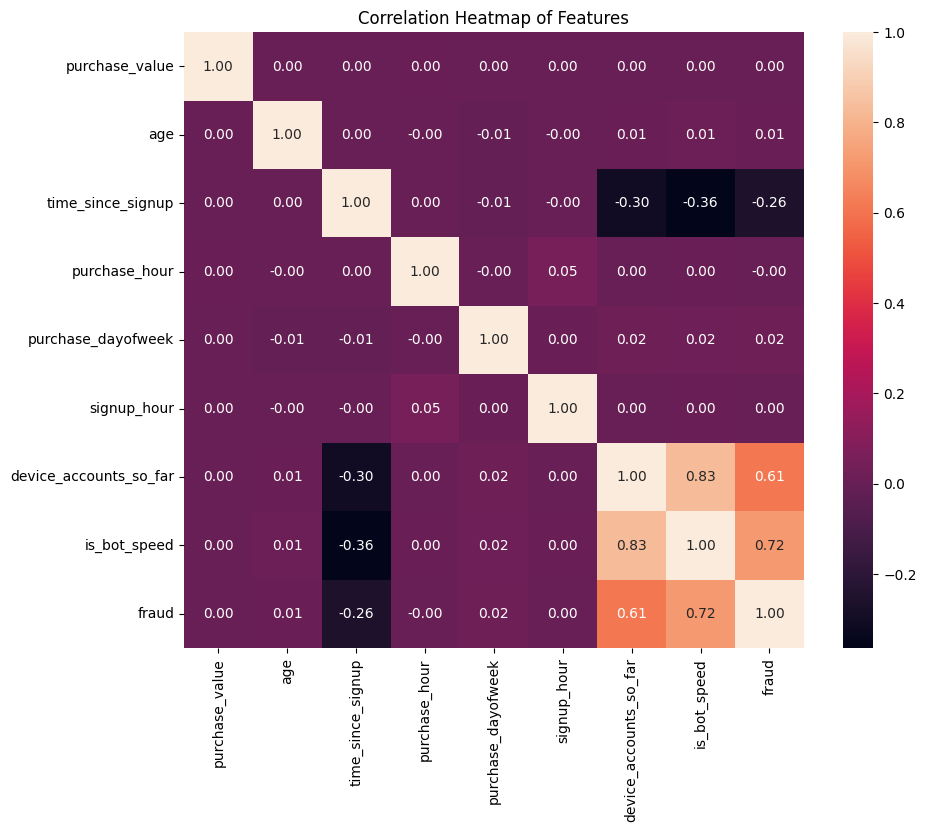

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

num_feats = X_train_enc.loc[:, X_train_enc.nunique() > 2]
num_feats = num_feats.assign(is_bot_speed=X_train_enc['is_bot_speed'])
corr = num_feats.assign(fraud=y_train.values).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='rocket')
plt.title('Correlation Heatmap of Features')
plt.show()

### **Step 36: Confusion matrix of the final model**

In [ ]:
import joblib
from sklearn.metrics import confusion_matrix, classification_report

model = joblib.load('fraud_model_xgb_final.pkl')
scores = model.predict_proba(X_test_p)[:, 1]

for name, cut in [('High cutoff (0.5)', 0.5), ('Medium cutoff (0.1)', 0.1)]:
    pred = (scores >= cut).astype(int)
    print(name)
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3))

High cutoff (0.5)
[[20540     5]
 [  967  1155]]
              precision    recall  f1-score   support

           0      0.955     1.000     0.977     20545
           1      0.996     0.544     0.704      2122

    accuracy                          0.957     22667
   macro avg      0.975     0.772     0.840     22667
weighted avg      0.959     0.957     0.951     22667

Medium cutoff (0.1)
[[19204  1341]
 [  603  1519]]
              precision    recall  f1-score   support

           0      0.970     0.935     0.952     20545
           1      0.531     0.716     0.610      2122

    accuracy                          0.914     22667
   macro avg      0.750     0.825     0.781     22667
weighted avg      0.929     0.914     0.920     22667



### **Step 37: Download the model files**

In [ ]:
from google.colab import files
files.download('fraud_model_xgb_final.pkl')
files.download('model_config_final.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
xgb_p.save_model('fraud_model_xgb_final.json')

from google.colab import files
files.download('fraud_model_xgb_final.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>